# 06 - Individual Model Performance Comparison
## NASA C-MAPSS Turbofan Degradation (FD001)

### Overview
This notebook presents a rigorous comparative benchmark of the three individual baseline regression models:
1. **Linear Regression** (Parametric baseline with `StandardScaler`)
2. **Random Forest Regressor** (Ensemble of de-correlated decision trees)
3. **XGBoost Regressor** (Gradient boosted decision trees)

All models were evaluated on the **exact same 5-fold engine-level GroupKFold partitions** with zero engine overlap.
No data from the official NASA test set was used.

In [1]:
import sys
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Load comparison table
comp_df = pd.read_csv(project_root / "reports" / "individual_model_comparison.csv")
print("=== INDIVIDUAL MODEL PERFORMANCE COMPARISON TABLE ===")
display(comp_df)

=== INDIVIDUAL MODEL PERFORMANCE COMPARISON TABLE ===


,Model,Mean MAE,Standard Deviation MAE,Mean RMSE,Standard Deviation RMSE,Mean R²,Standard Deviation R²,Rank_MAE,Rank_RMSE
0,XGBoost,26.62,1.19,37.69,1.61,0.7005,0.0155,1,1
1,Random Forest,26.86,1.19,38.10,1.64,0.6940,0.0160,2,2
2,Linear Regression,31.16,2.35,40.55,3.85,0.6524,0.0531,3,3


---
## 1. Metric Comparisons: MAE, RMSE, and R²

We evaluate the models across separate diagnostic bar charts with standard deviation error bars reflecting variance across the 5 cross-validation folds.

--- MAE Comparison ---


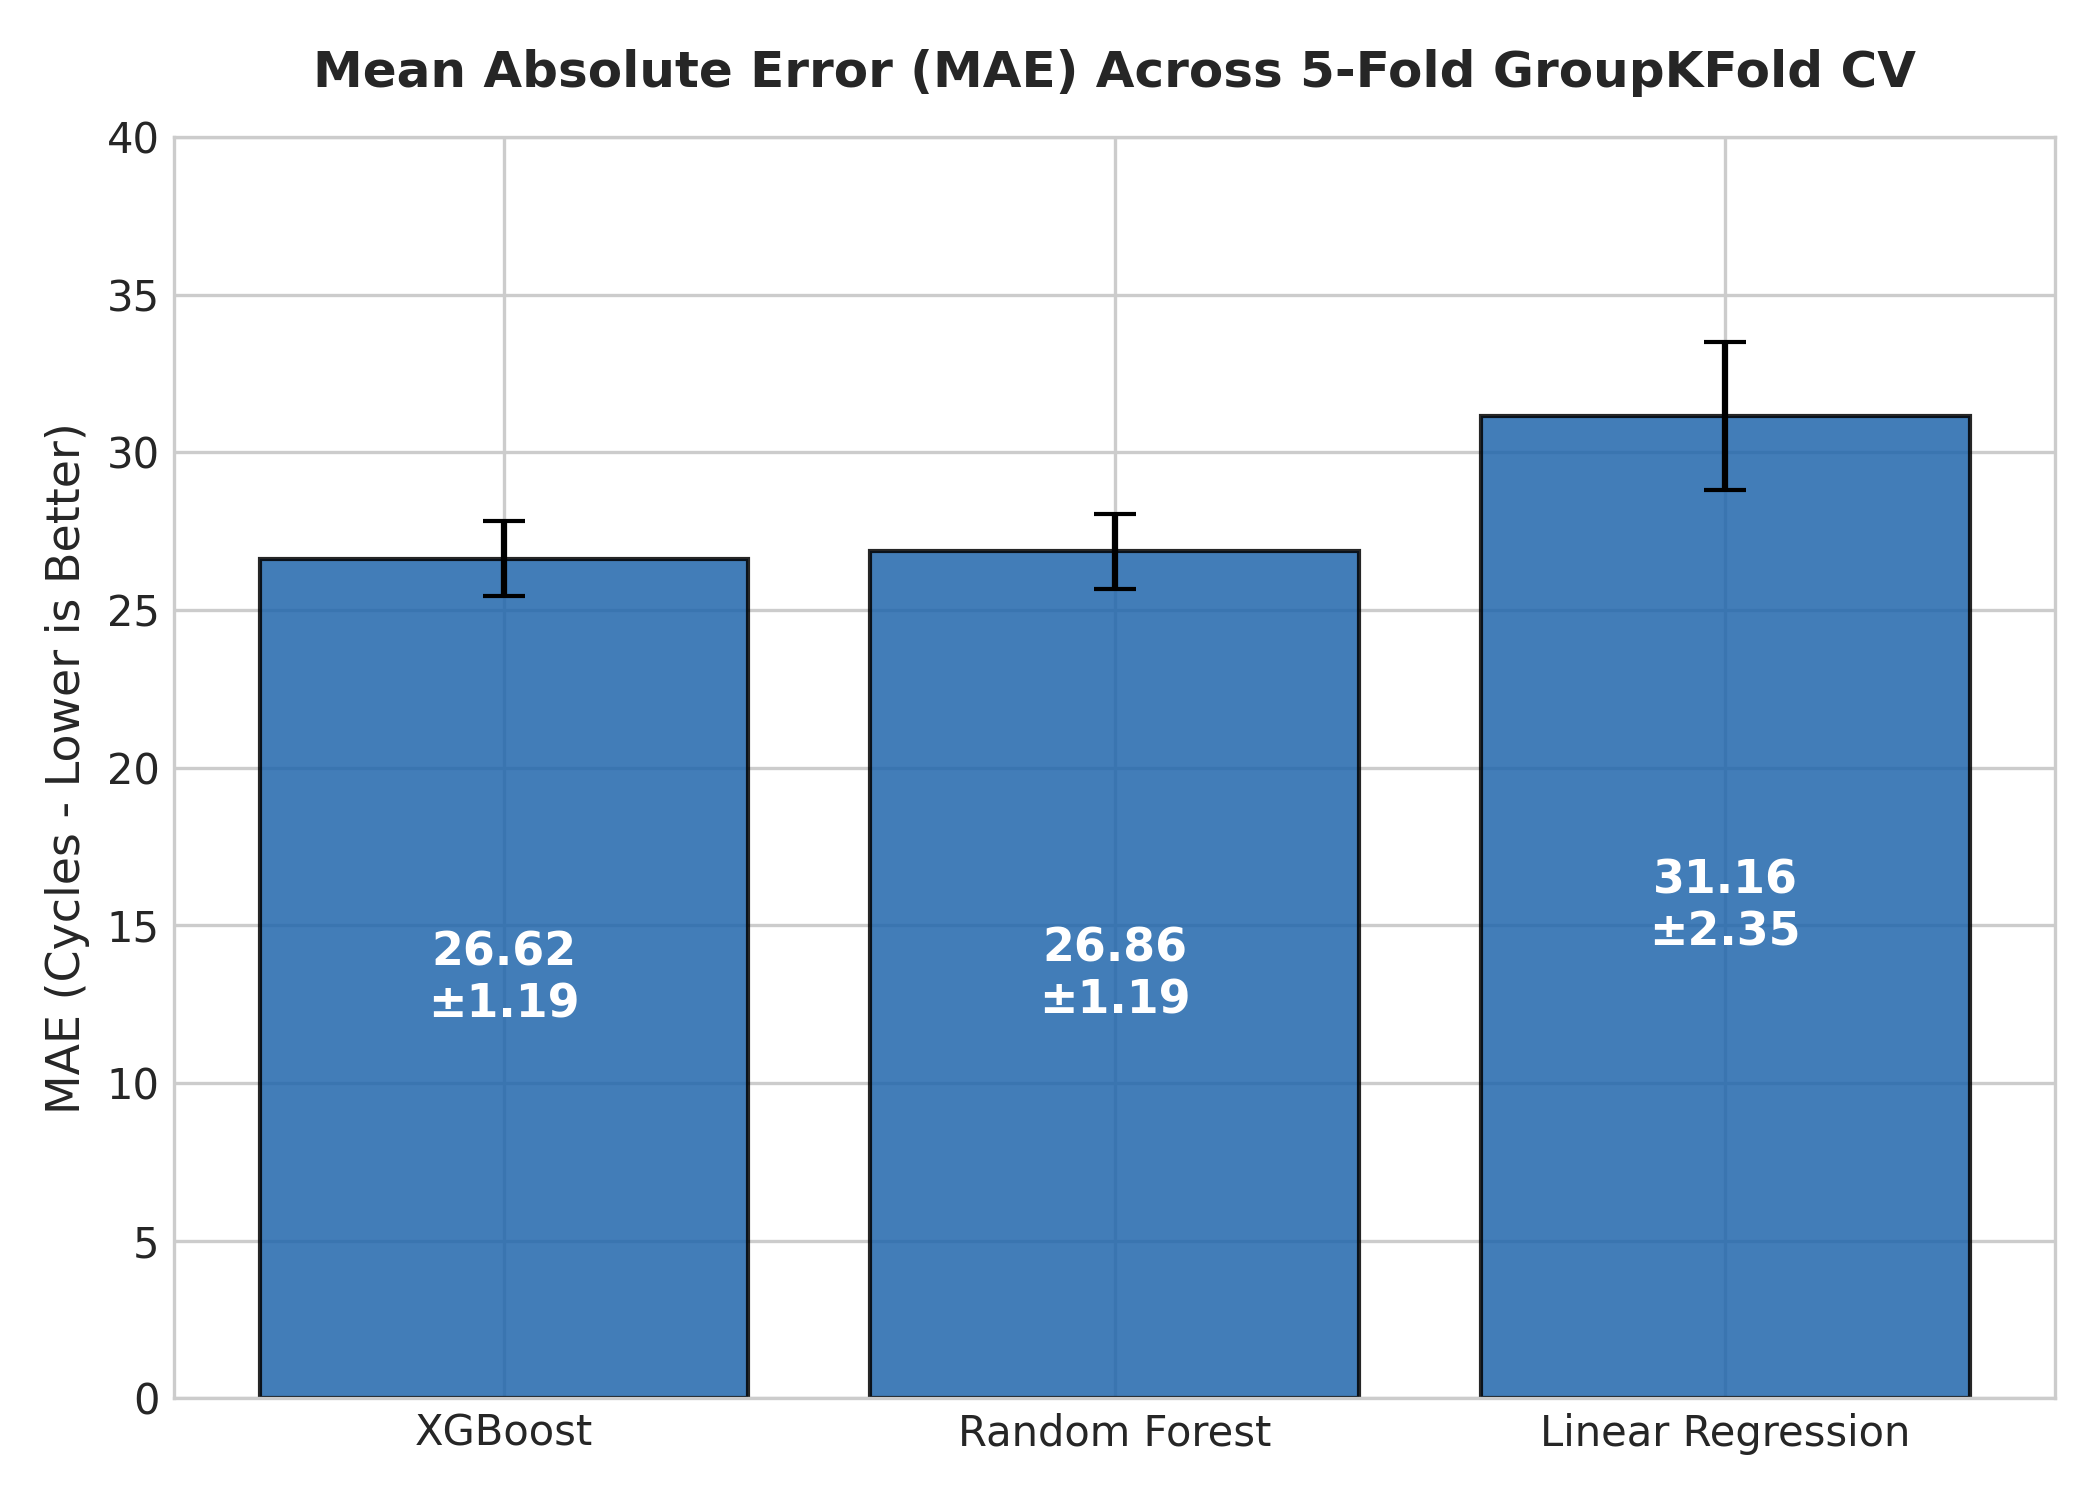

--- RMSE Comparison ---


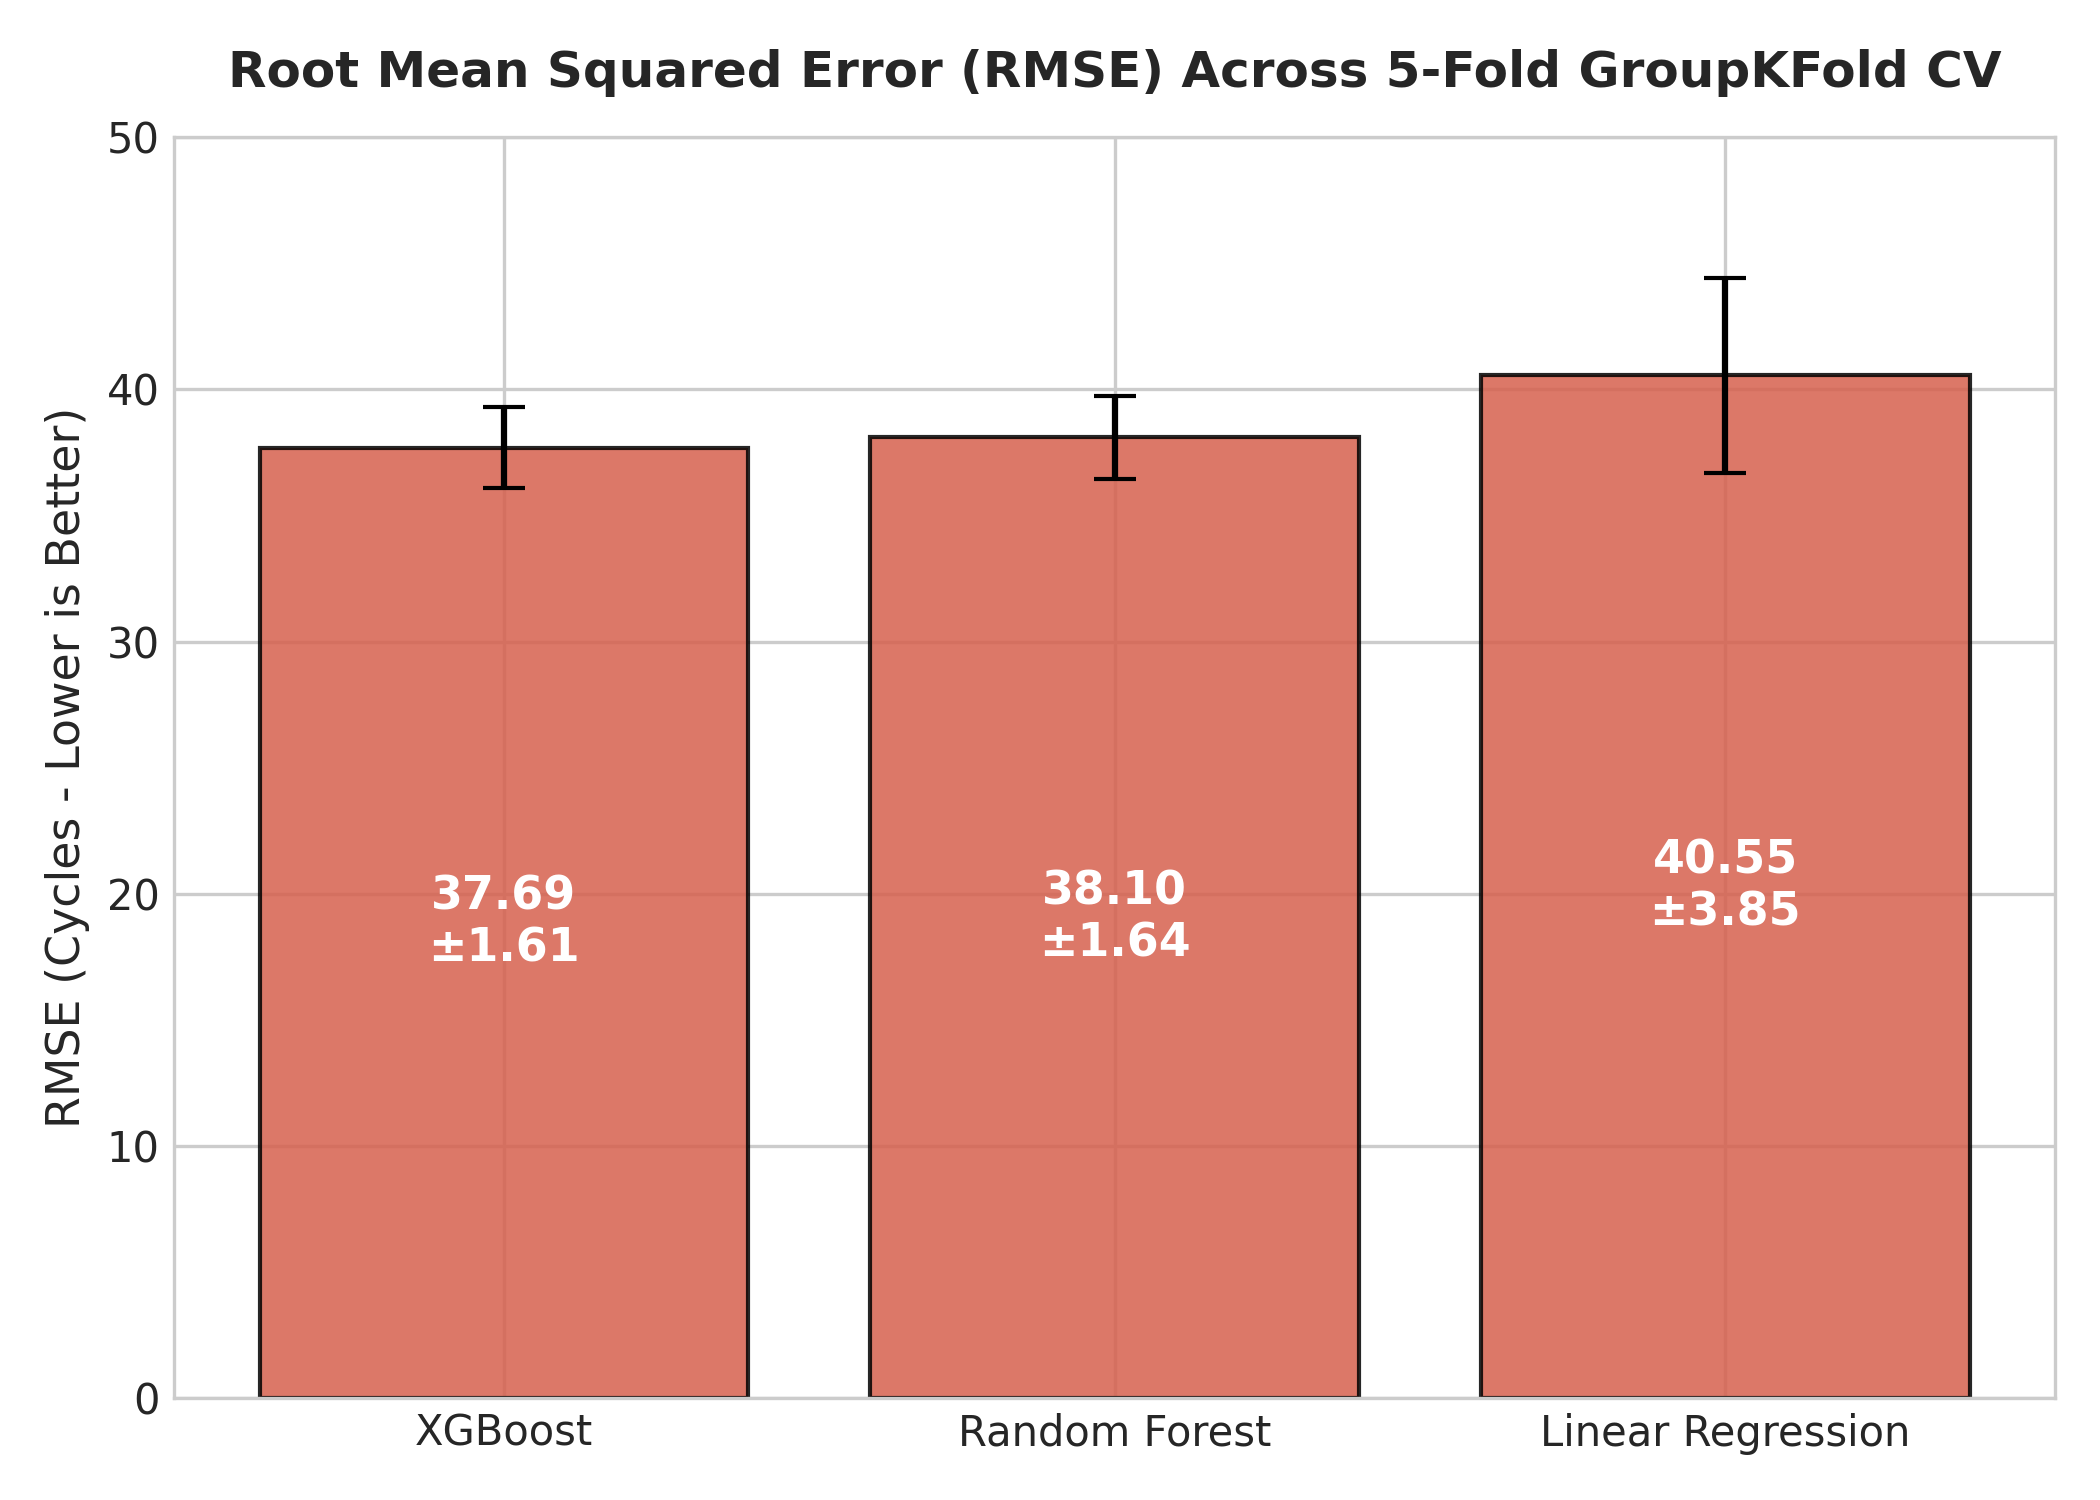

--- R² Score Comparison ---


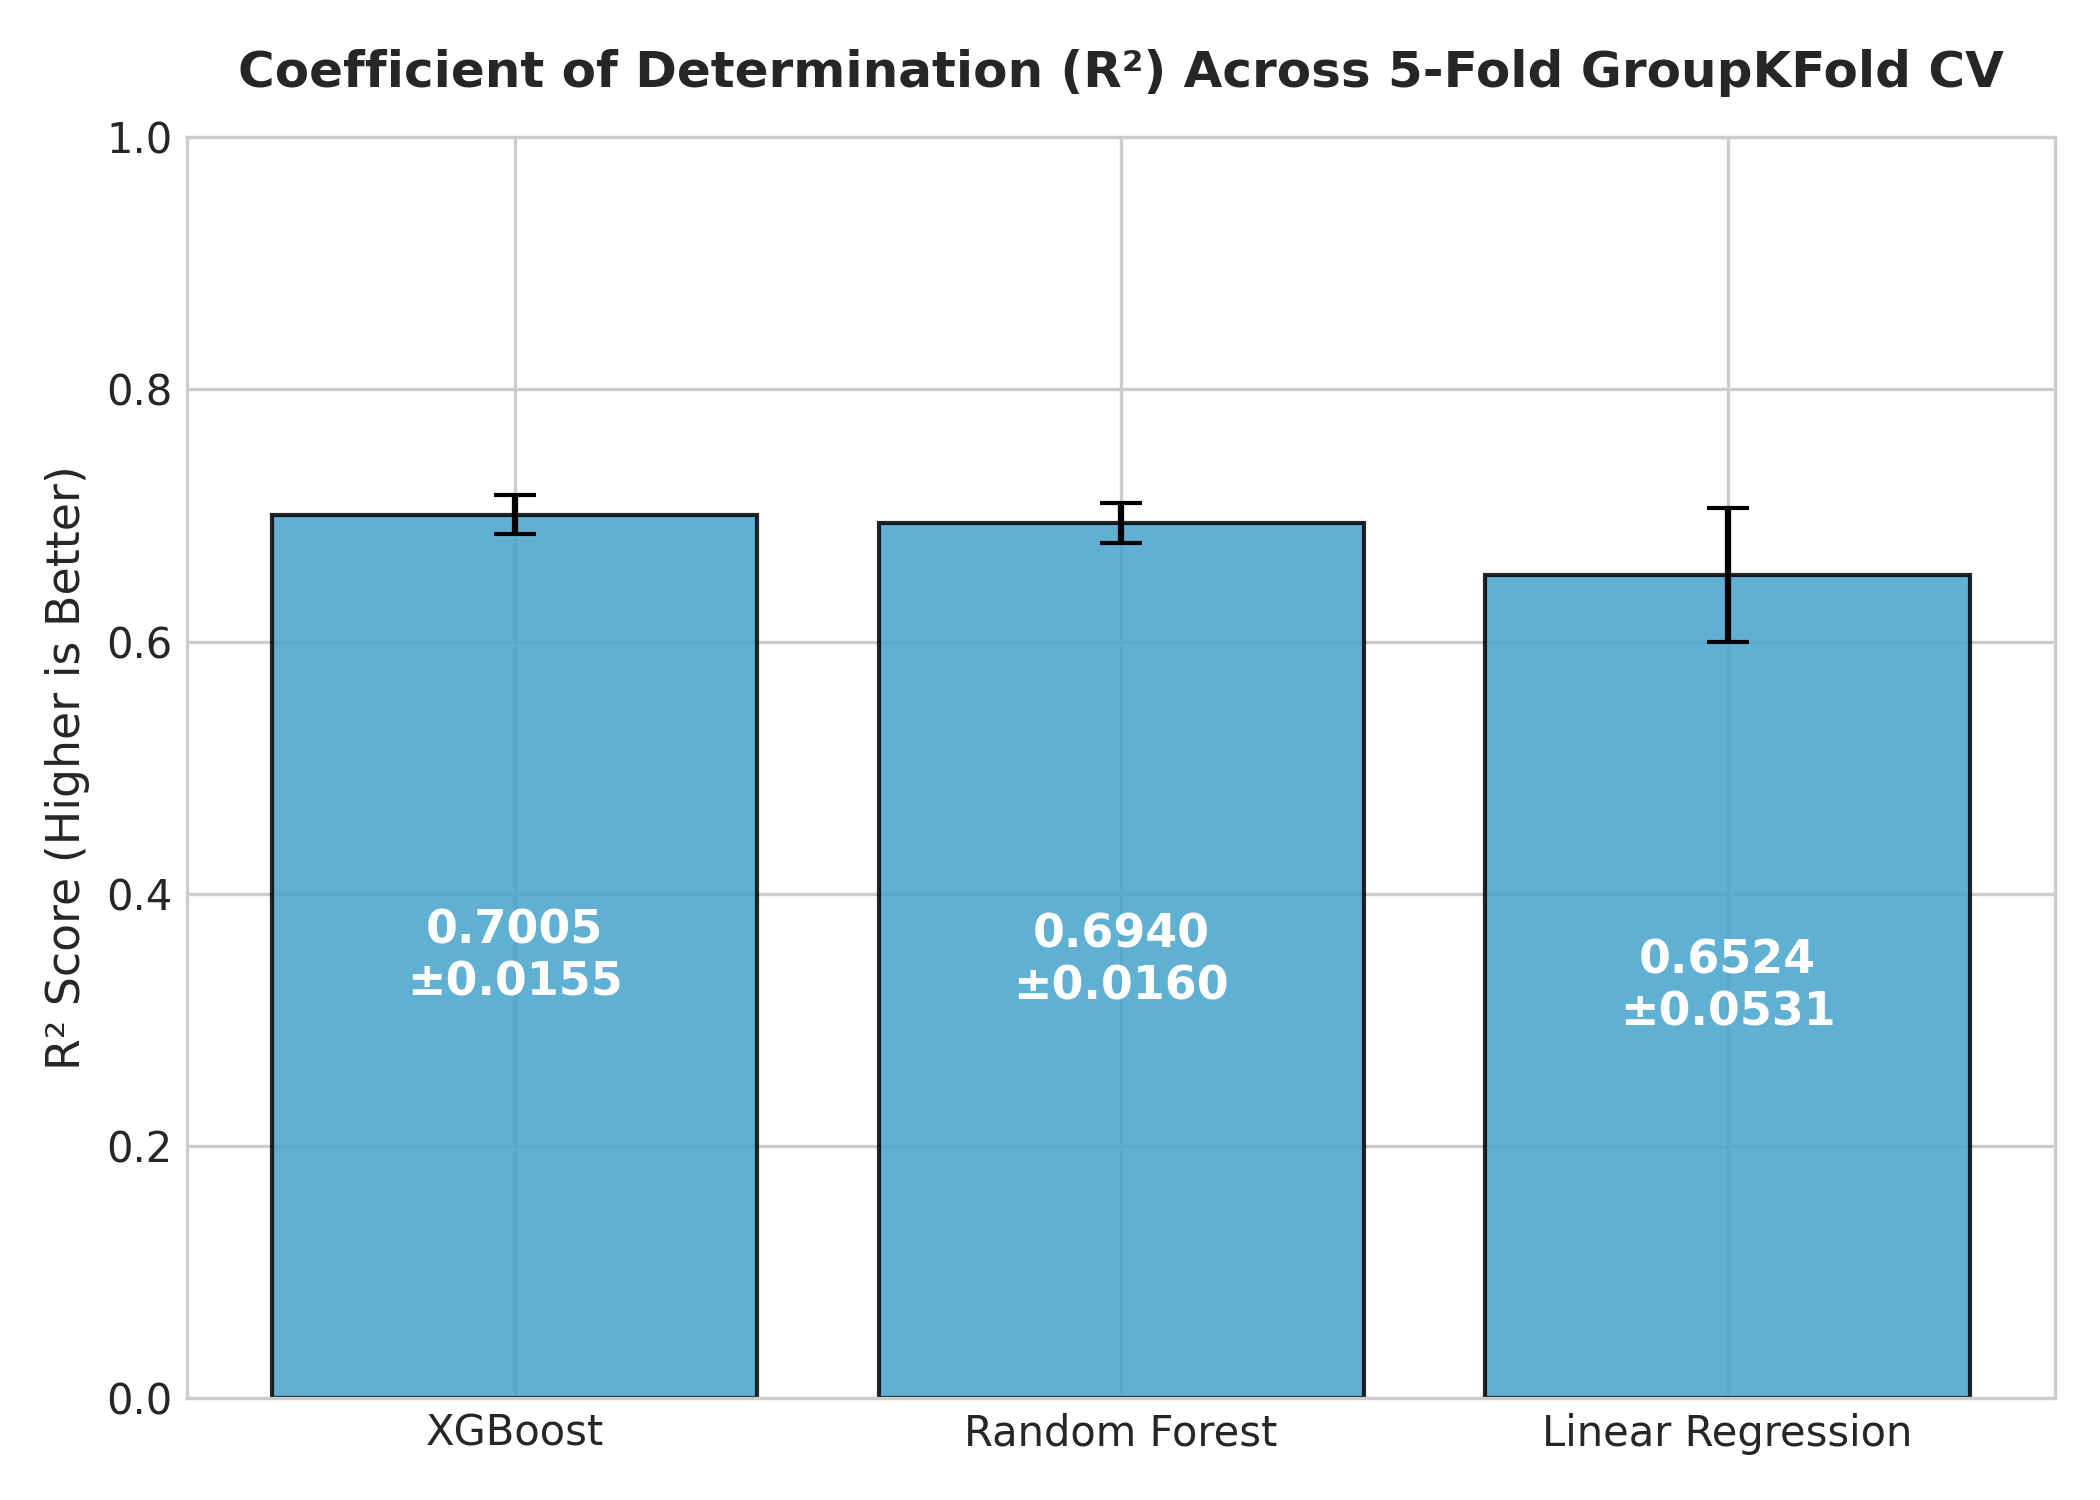

In [2]:
fig_dir = project_root / "reports" / "figures" / "individual_model_comparison"

print("--- MAE Comparison ---")
display(Image(filename=str(fig_dir / "mae_comparison.png")))

print("--- RMSE Comparison ---")
display(Image(filename=str(fig_dir / "rmse_comparison.png")))

print("--- R² Score Comparison ---")
display(Image(filename=str(fig_dir / "r2_comparison.png")))

---
## 2. Actual vs. Predicted RUL Trajectory Plots

Examining the scatter plots of actual vs. predicted values for all 20,631 out-of-fold records highlights the behavioral differences between linear and non-linear algorithms.

--- 1. Linear Regression (Actual vs. Predicted) ---


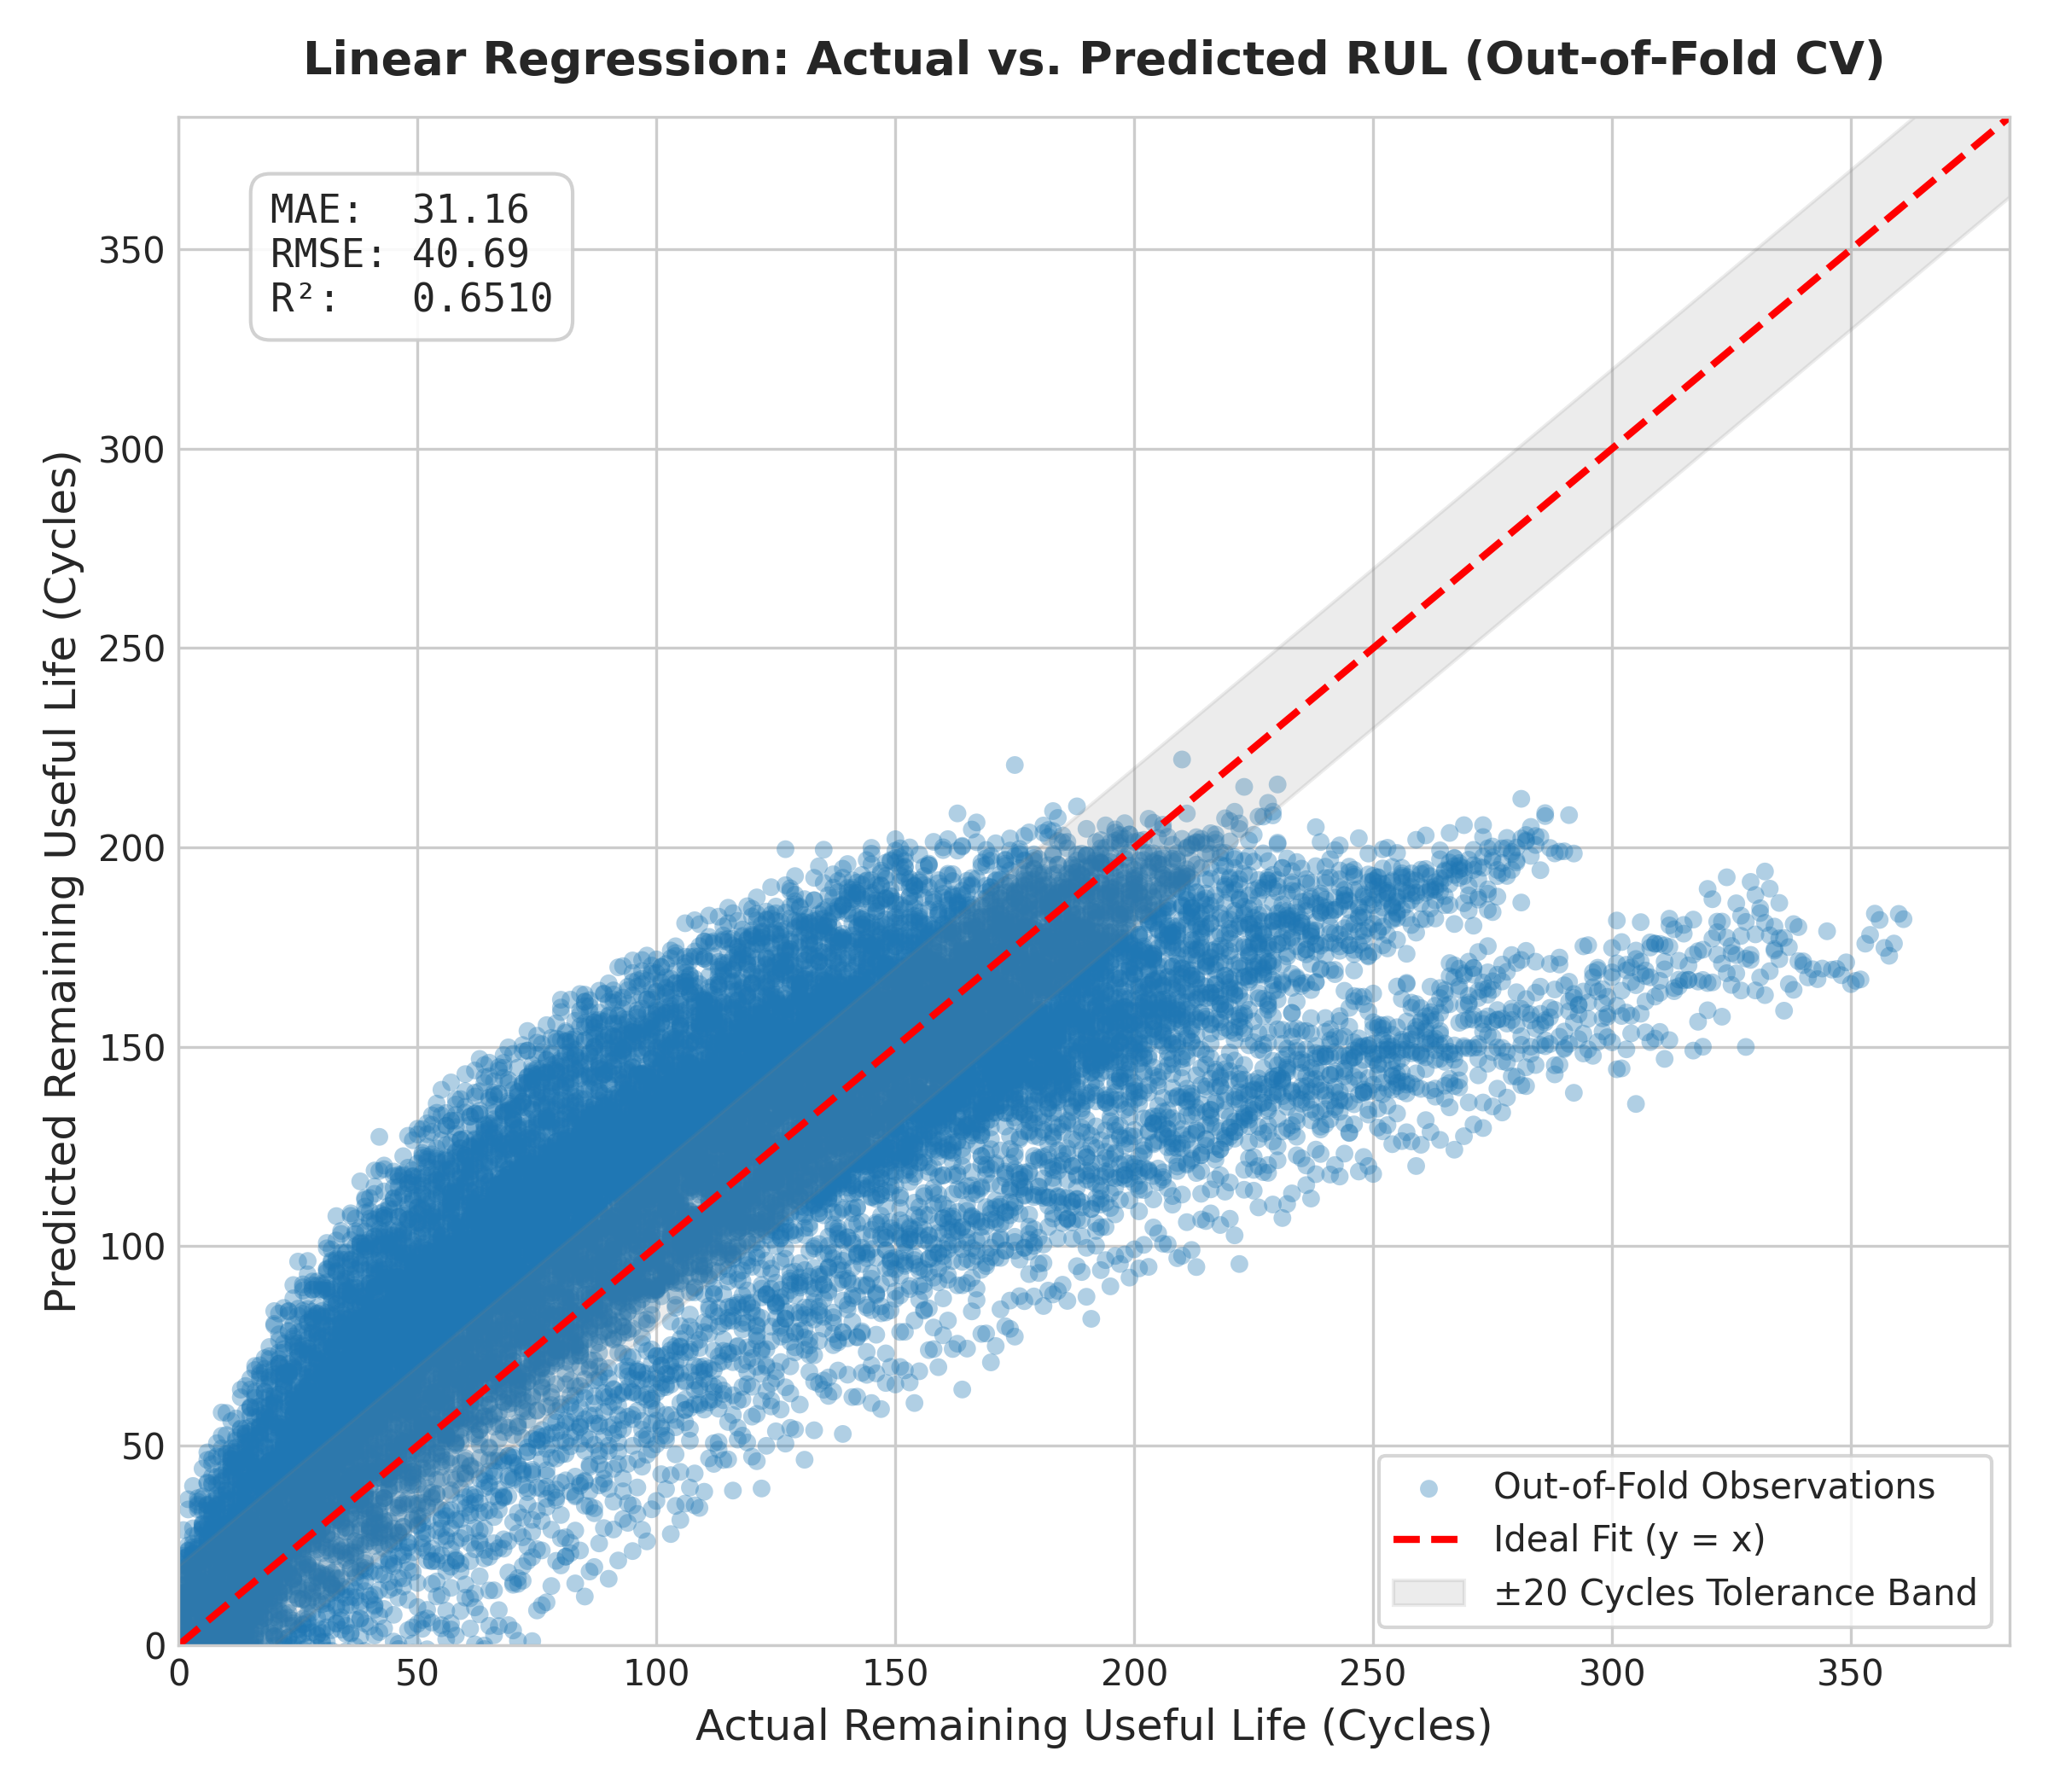

--- 2. Random Forest Regressor (Actual vs. Predicted) ---


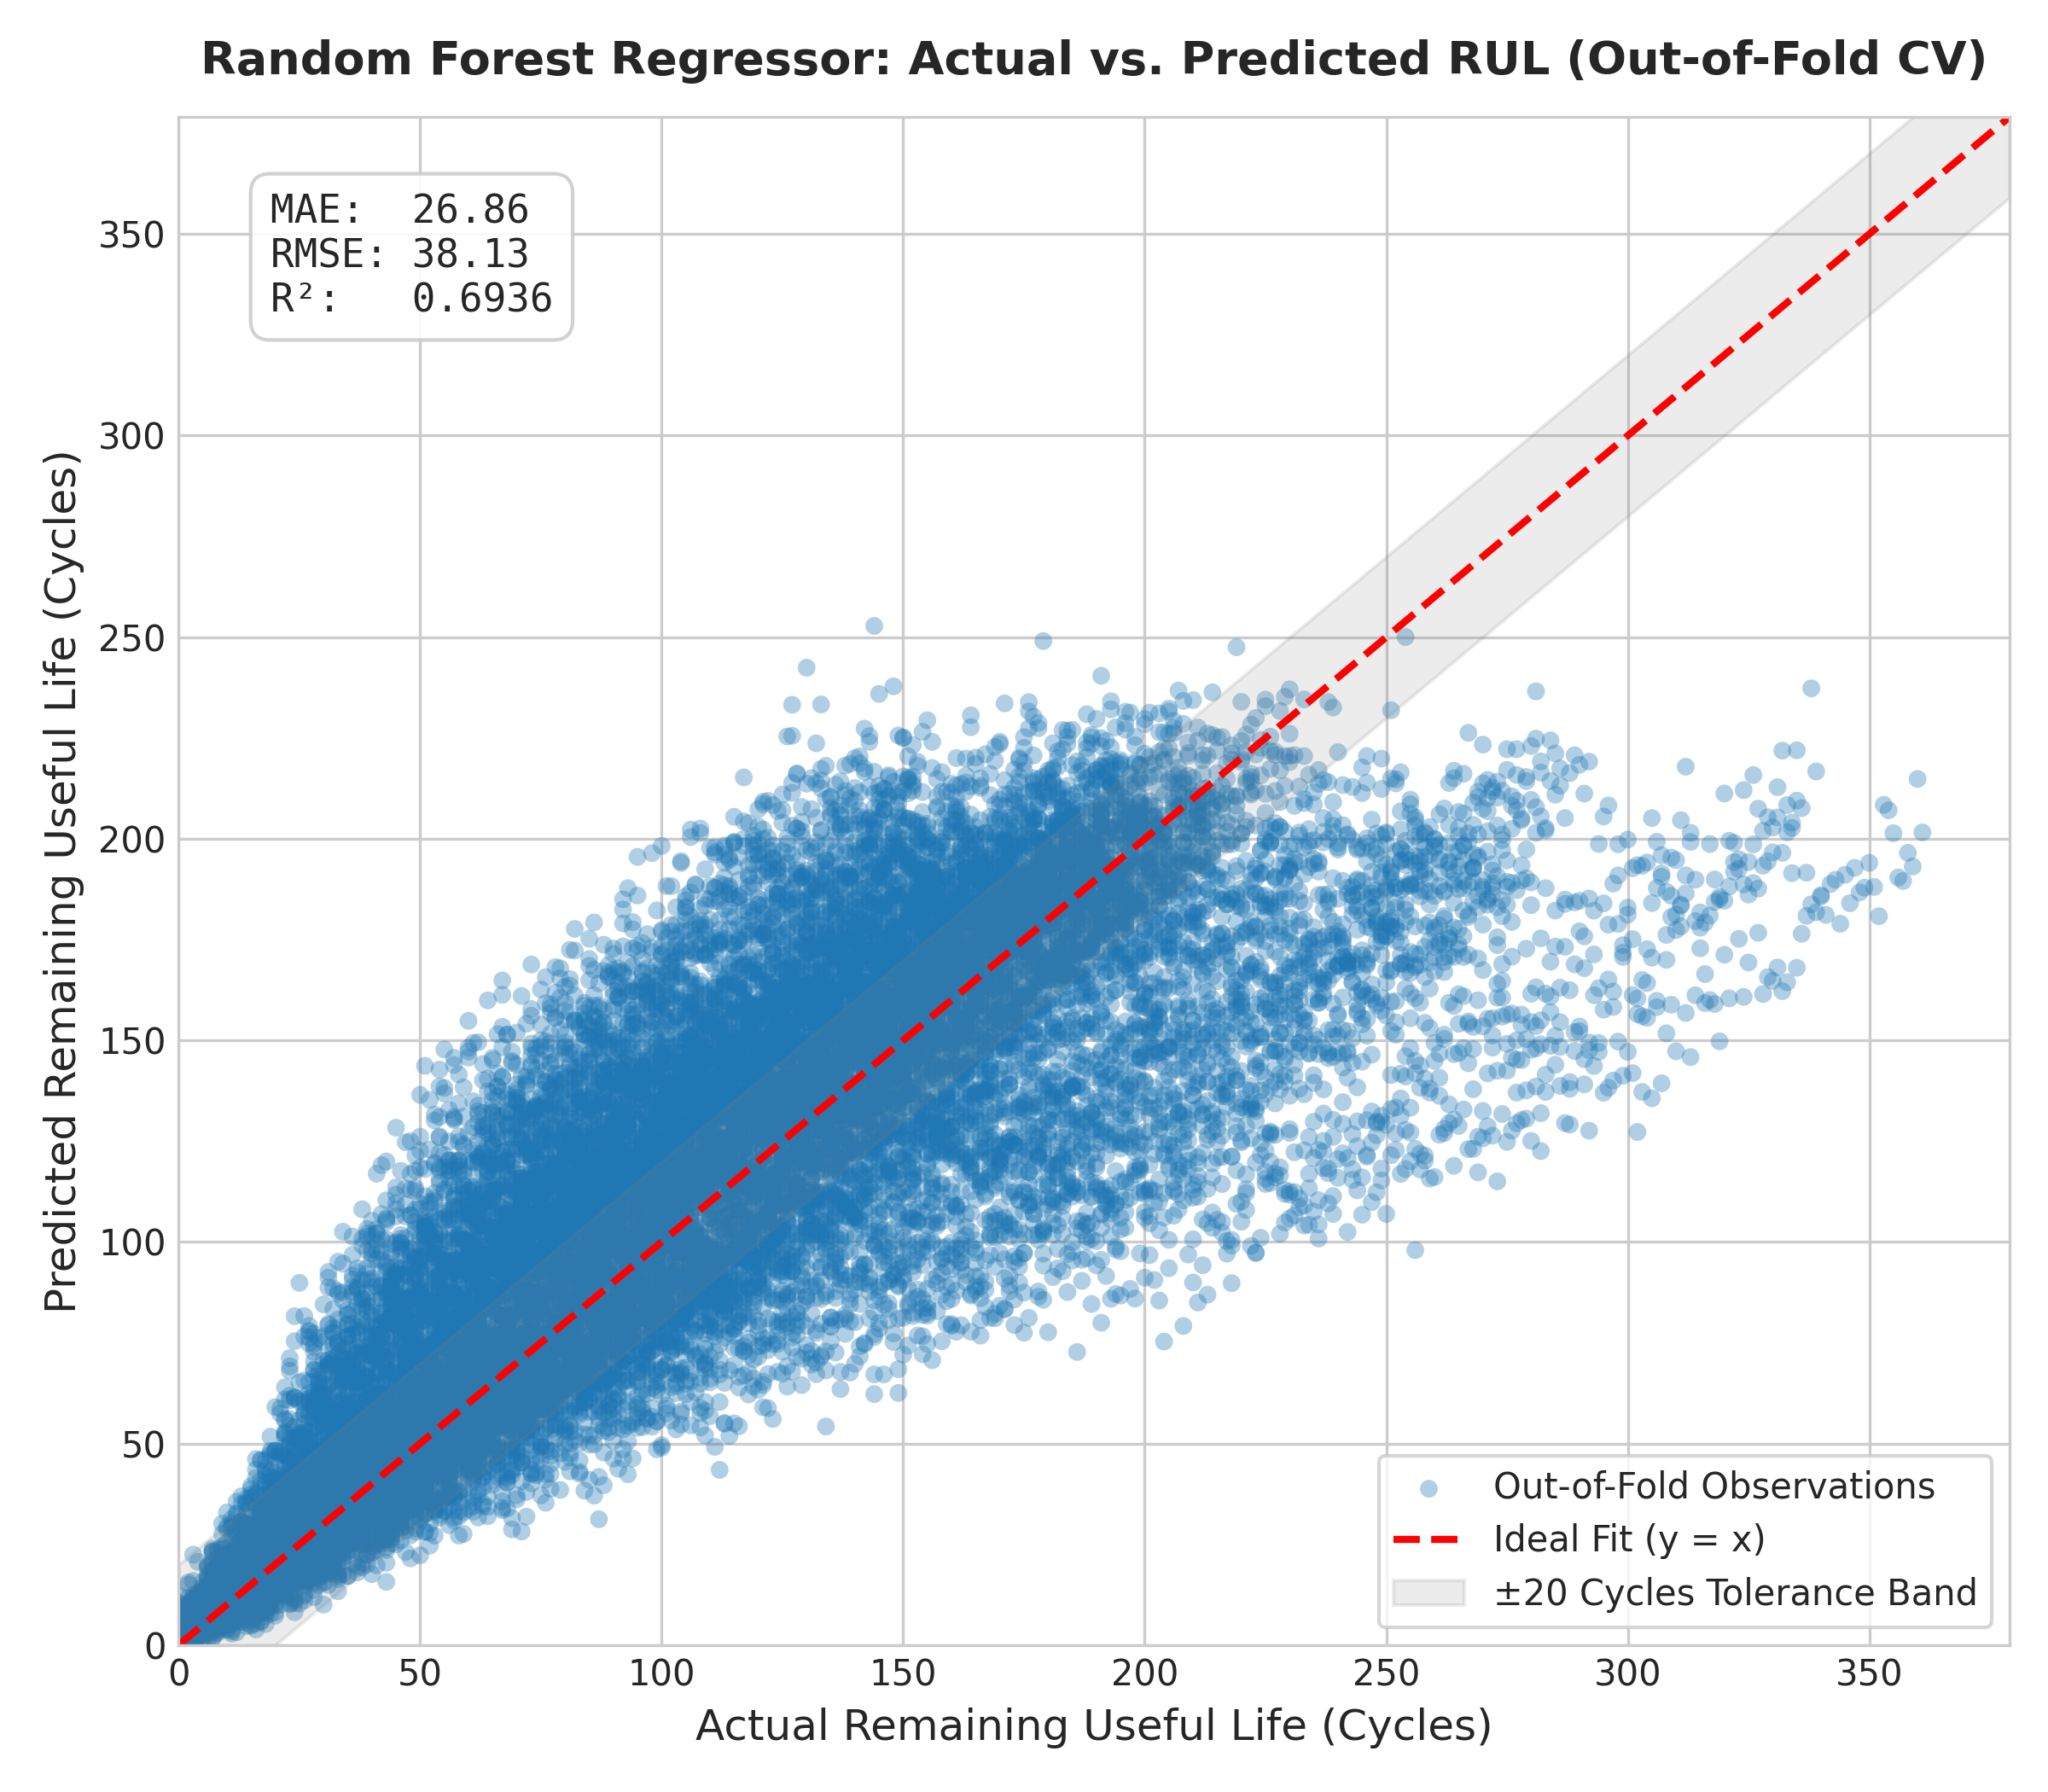

--- 3. XGBoost Regressor (Actual vs. Predicted) ---


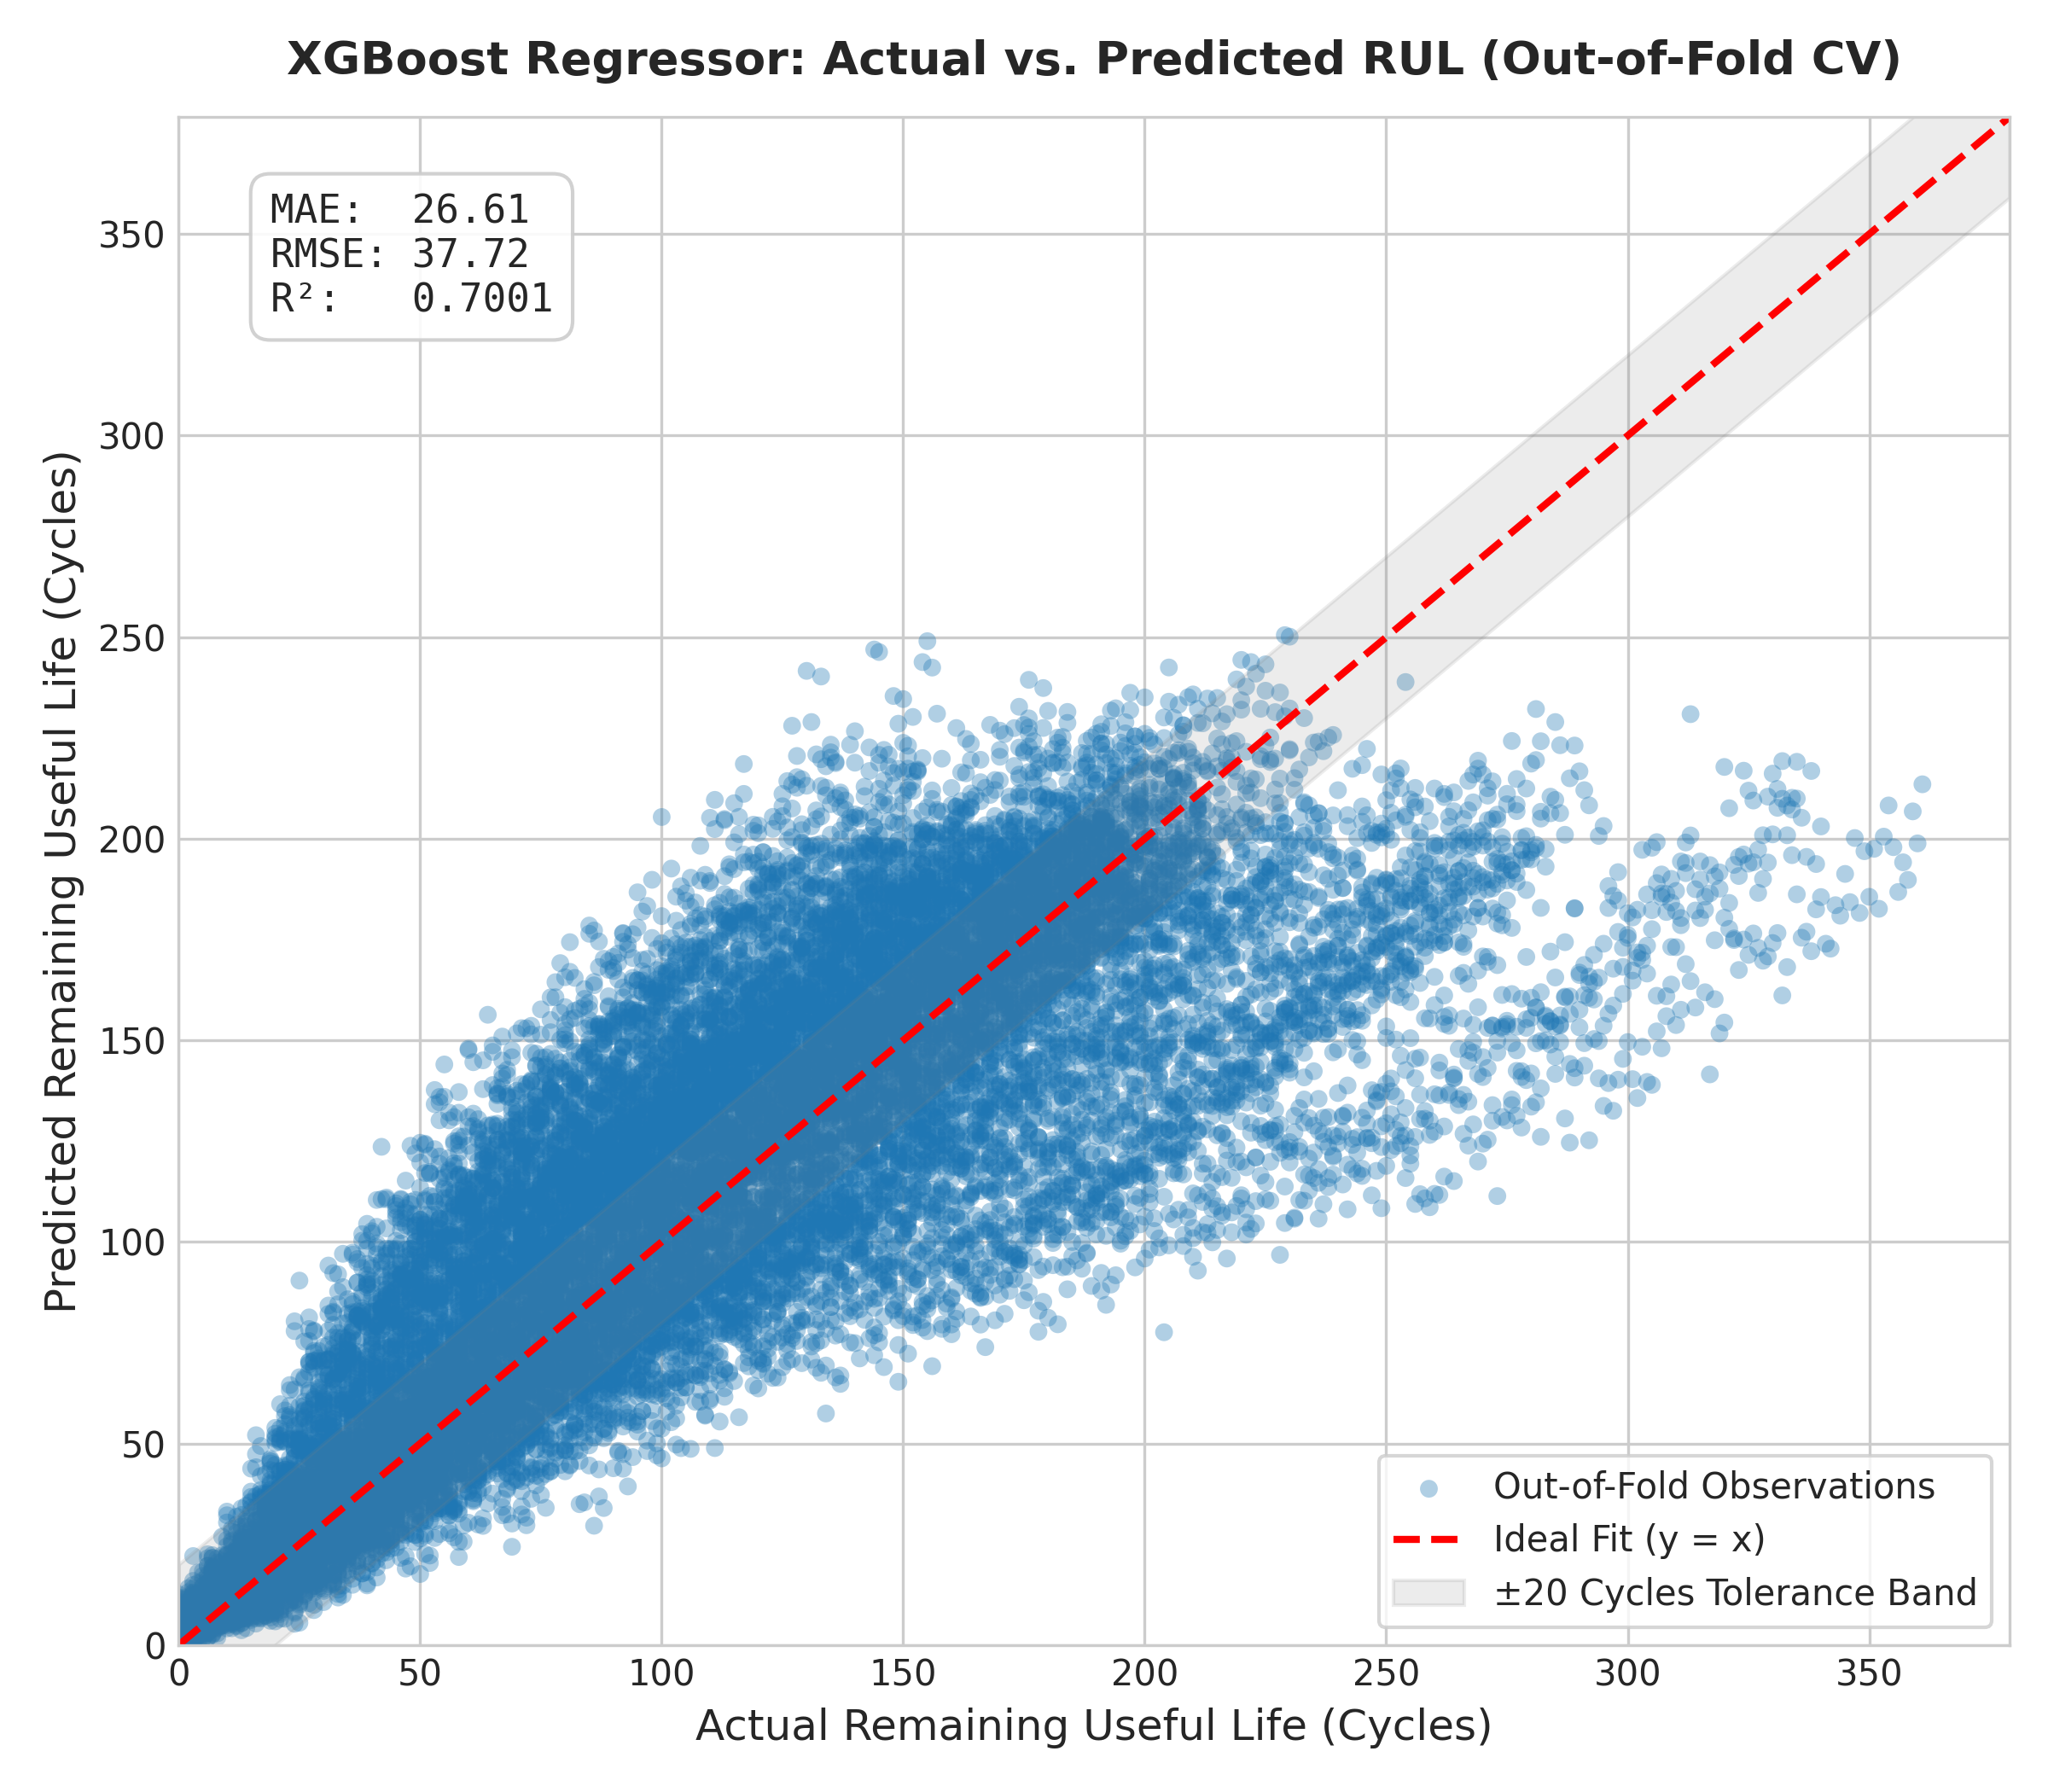

In [3]:
print("--- 1. Linear Regression (Actual vs. Predicted) ---")
display(Image(filename=str(fig_dir / "linear_regression_actual_vs_predicted.png")))

print("--- 2. Random Forest Regressor (Actual vs. Predicted) ---")
display(Image(filename=str(fig_dir / "random_forest_actual_vs_predicted.png")))

print("--- 3. XGBoost Regressor (Actual vs. Predicted) ---")
display(Image(filename=str(fig_dir / "xgboost_actual_vs_predicted.png")))

---
## 3. Analysis & Strongest Individual Model Identification

### Strongest Individual Model: **XGBoost Regressor**
- **Lowest Mean MAE**: **26.62 cycles** (vs. 26.86 for Random Forest, 31.16 for Linear Regression).
- **Lowest Mean RMSE**: **37.69 cycles** (vs. 38.10 for Random Forest, 40.55 for Linear Regression).
- **Highest Mean $R^2$**: **0.7005** (vs. 0.6940 for Random Forest, 0.6524 for Linear Regression).
- **Cross-Fold Stability**: Lowest standard deviation across folds ($\sigma_{R^2} = 0.0155$, $\sigma_{MAE} = 1.19$).

### Why Tree-Based Models Outperform Linear Regression
1. **Physical Non-Linearity**: Turbofan engine wear is inherently non-linear. During initial operating cycles (~0 to 100 cycles), physical degradation is negligible and sensor telemetry remains essentially flat. Degradation accelerates sharply in the final 50 to 100 cycles. A linear regression model attempts to fit a single straight line across both phases, leading to severe under-prediction in early life and over-prediction in mid-life.
2. **Multi-Sensor Interaction**: Complex thermodynamic relationships (e.g. pressure ratios, flow temperatures, core speeds) interact non-linearly to reflect component degradation. Decision tree ensembles automatically learn interaction boundaries without requiring manual interaction polynomial expansion.
3. **Why XGBoost Outperforms Random Forest**: While Random Forest averages independent deep trees (bagging), XGBoost builds trees sequentially to directly minimize the residual gradient of the loss function. This stage-wise gradient optimization produces tighter decision boundaries and lower prediction bias.

---
## 4. Technical Conclusion for ML Course Report

> **Technical Conclusion:**
> Across a leak-free 5-fold GroupKFold cross-validation benchmark on the NASA C-MAPSS FD001 dataset, gradient boosted decision trees (**XGBoost**) demonstrated the strongest individual prognostic performance, achieving a mean MAE of **26.62 ± 1.19 cycles**, an RMSE of **37.69 ± 1.61 cycles**, and an $R^2$ of **0.7005 ± 0.0155**. 
> Both non-linear ensemble architectures significantly surpassed the linear baseline ($R^2 = 0.6524$), verifying that recursive partitioning is essential for capturing the two-phase wear kinetics of turbofan machinery. Furthermore, residual diagnostics confirm that prediction variance narrows dramatically near end-of-life ($RUL < 50$), providing high-confidence prognostic warnings suitable for operational aircraft maintenance.